# Seguimiento evaluativo (10 %): Árboles de decisión para regresión con Iris

**Estudiante:** Alexander Mejía Ospina
**Asignatura:** Analítica de Datos — Ingeniería de Software, séptimo semestre
**Docente:** Luis Miguel Gómez Meneses
**Universidad Cooperativa de Colombia — Medellín**

## Objetivo

Construir un **árbol de regresión** que prediga la **longitud del pétalo** (en centímetros) de una flor Iris a partir
de la longitud del sépalo, el ancho del sépalo y el ancho del pétalo; justificar la profundidad del árbol mediante
**validación cruzada KFold** sobre entrenamiento, y evaluar el modelo elegido **una sola vez** sobre los datos de prueba.

## Ruta de trabajo

1. Consulta del método (árbol de regresión, `max_depth` y sobreajuste).
2. Carga y exploración de los datos.
3. Definición de X e y y separación 80/20.
4. Comparación de profundidades (1, 2, 3, 4 y sin límite) con KFold de 5 particiones.
5. Entrenamiento del modelo seleccionado y evaluación final en prueba.
6. Interpretación, respuestas a las preguntas guía y conclusión.
7. Referencias.

## 1. Consulta del método

### 1.1 ¿Qué es un árbol de regresión?

Un árbol de regresión es un modelo supervisado que predice una **variable numérica continua** dividiendo el espacio
de los predictores en regiones rectangulares mediante preguntas sucesivas del tipo *"¿ancho del pétalo ≤ 0,80 cm?"*.
Cada observación recorre el árbol desde la **raíz**, siguiendo las ramas según sus valores, hasta llegar a una **hoja**.

**¿Cómo elige las divisiones?** En cada nodo, el algoritmo (CART, implementado en scikit-learn) prueba todas las variables
y umbrales posibles y escoge la división que más reduce el **error cuadrático** dentro de los nodos hijos. Con
`criterion="squared_error"` la impureza de un nodo es la varianza de *y* en ese nodo:

$$\text{MSE}(nodo) = \frac{1}{n}\sum_{i \in nodo}(y_i - \bar{y}_{nodo})^2$$

y se elige la división que minimiza el promedio ponderado (por número de observaciones) de esa impureza en los dos hijos.

**¿Qué predice una hoja?** El **promedio** de los valores de *y* de las observaciones de entrenamiento que cayeron en
esa hoja. Ese promedio es justamente el valor constante que minimiza el error cuadrático dentro de la hoja. Por eso el
árbol produce una función **escalonada**: todas las flores que llegan a la misma hoja reciben exactamente la misma
predicción (en centímetros).

### 1.2 Diferencias con otros métodos

| Aspecto | Árbol de regresión | Árbol de clasificación | Regresión lineal |
|---|---|---|---|
| Tipo de salida | Número continuo (cm) | Categoría (especie) | Número continuo |
| Valor de una hoja | Promedio de *y* en la hoja | Clase más frecuente (y proporciones) | No tiene hojas |
| Criterio de división | Reducción del error cuadrático (varianza) | Reducción de la impureza (Gini o entropía) | No divide: estima coeficientes por mínimos cuadrados |
| Forma de la función | Escalonada, por regiones; capta no linealidades e interacciones | Fronteras rectangulares entre clases | Un hiperplano: $\hat y = \beta_0 + \beta_1x_1 + \dots + \beta_px_p$ |
| Extrapolación | No predice fuera del rango de *y* visto en entrenamiento | — | Sí extrapola (puede dar valores fuera del rango) |
| Métricas típicas | MAE, RMSE, R² | Exactitud, matriz de confusión | MAE, RMSE, R² |

La palabra *regresión* se refiere al **tipo de salida** (numérica), no a que el modelo sea lineal. La regresión lineal
asume que cada predictor tiene un efecto constante (pendiente) en todo el rango; el árbol, en cambio, aprende reglas
locales y no supone ninguna forma funcional.

### 1.3 ¿Qué controla `max_depth` y cómo se relaciona con el sobreajuste?

`max_depth` es un **hiperparámetro** (se fija antes de entrenar, no lo aprende el modelo) que limita el número máximo
de preguntas desde la raíz hasta una hoja. Con profundidad *d* el árbol tiene como máximo $2^d$ hojas, es decir,
como máximo $2^d$ valores de predicción distintos.

- **Profundidad pequeña → subajuste (alto sesgo):** pocas hojas, predicciones muy gruesas; el error es alto tanto en
  entrenamiento como en validación.
- **Profundidad grande o `None` → sobreajuste (alta varianza):** el árbol sigue dividiendo hasta que las hojas son
  casi puras (o no se puede dividir más). Memoriza el entrenamiento (error casi cero) pero aprende ruido que no se
  repite en datos nuevos, y el error de validación deja de bajar o sube.
- `max_depth=None` significa **sin límite máximo**: el árbol crece hasta que otros criterios de parada lo detienen
  (por defecto `min_samples_split=2`), no que crezca indefinidamente.

Por eso la profundidad se escoge con **validación cruzada** sobre entrenamiento, buscando el punto de equilibrio
entre sesgo y varianza, y nunca mirando el conjunto de prueba.

*Fuentes: documentación de scikit-learn (Decision Trees, `DecisionTreeRegressor`), Breiman et al. (1984) y James et al.
(2021), cap. 8. Ver la sección de referencias al final.*

## 2. Importación de librerías y semilla

- **pandas / numpy:** manipulación de datos y tablas.
- **matplotlib:** gráficos.
- **scikit-learn:** datos Iris, separación, validación cruzada, árbol de regresión y métricas.

Se fija `SEMILLA = 42` para que la separación, los pliegues y el árbol sean reproducibles.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEMILLA = 42
pd.set_option("display.precision", 3)

## 3. Carga y exploración de los datos

Se carga Iris desde scikit-learn y se renombran las columnas en español. La especie se agrega **solo para explorar**
los datos; no se usará como predictor ni como objetivo.

In [2]:
iris = load_iris()
columnas = ["longitud_sepalo", "ancho_sepalo", "longitud_petalo", "ancho_petalo"]

datos = pd.DataFrame(iris.data, columns=columnas)
datos["especie"] = iris.target_names[iris.target]

display(datos.head())
print(f"Dimensiones: {datos.shape[0]} filas x {datos.shape[1]} columnas")

,longitud_sepalo,ancho_sepalo,longitud_petalo,ancho_petalo,especie
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Dimensiones: 150 filas x 5 columnas


**Interpretación.** El conjunto tiene **150 filas** (cada fila es una flor) y **5 columnas**: cuatro medidas en
centímetros y la especie.

In [3]:
print("Tipos de variables:")
print(datos.dtypes)
print("\nFlores por especie:")
print(datos["especie"].value_counts())

Tipos de variables:
longitud_sepalo    float64
ancho_sepalo       float64
longitud_petalo    float64
ancho_petalo       float64
especie             object
dtype: object

Flores por especie:
especie
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


**Interpretación.** Las cuatro medidas son **numéricas continuas** (`float64`, en cm). La especie es **categórica
nominal** (`object`, o `str` en versiones recientes de pandas) con tres niveles balanceados (50 flores cada uno). En esta actividad:

- **y (objetivo):** `longitud_petalo` → numérica continua, por eso el problema es de **regresión**.
- **X (predictores):** `longitud_sepalo`, `ancho_sepalo`, `ancho_petalo`.
- **Excluida:** `especie`. Predecir la especie sería clasificación, que no es el objetivo; además, usarla como entrada
  exigiría conocer la especie de una flor nueva, que es justamente lo que no se mide en este escenario.

In [4]:
seleccionadas = ["longitud_sepalo", "ancho_sepalo", "ancho_petalo", "longitud_petalo"]
resumen = datos[seleccionadas].describe().T
resumen["rango"] = resumen["max"] - resumen["min"]
display(resumen.round(3))

,count,mean,std,min,25%,50%,75%,max,rango
longitud_sepalo,150.0,5.843,0.828,4.3,5.1,5.80,6.4,7.9,3.6
ancho_sepalo,150.0,3.057,0.436,2.0,2.8,3.00,3.3,4.4,2.4
ancho_petalo,150.0,1.199,0.762,0.1,0.3,1.30,1.8,2.5,2.4
longitud_petalo,150.0,3.758,1.765,1.0,1.6,4.35,5.1,6.9,5.9


**Interpretación del resumen.**

- La **longitud del pétalo** (objetivo) va de 1,0 a 6,9 cm, con media ≈ 3,76 cm y desviación estándar ≈ 1,77 cm. Es la
  variable con mayor dispersión, y su mediana (4,35 cm) está muy por encima de la media: la distribución es
  **bimodal** (pétalos cortos de *setosa* frente a pétalos largos de *versicolor* y *virginica*).
- El **ancho del pétalo** (0,1 a 2,5 cm) también presenta mucha dispersión relativa; el **ancho del sépalo**
  (2,0 a 4,4 cm) es la variable más concentrada.
- No se observan valores imposibles (negativos o cero) ni magnitudes extrañas.

Esta desviación estándar de 1,77 cm sirve como referencia: un modelo útil debe cometer errores **mucho menores** que esa
variación natural.

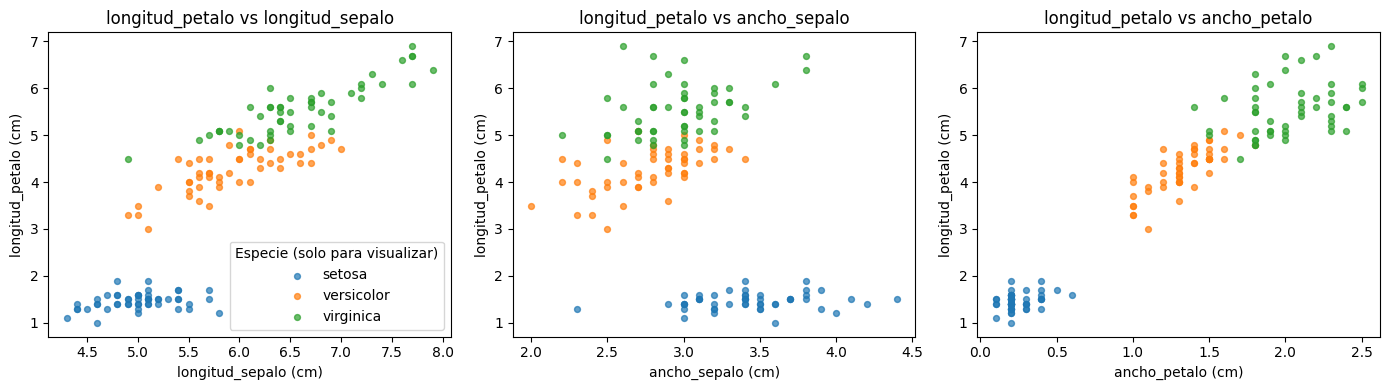

Correlación de Pearson de cada predictor con la longitud del pétalo:
longitud_sepalo    0.872
ancho_sepalo      -0.428
ancho_petalo       0.963
Name: longitud_petalo, dtype: float64


In [5]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
predictores = ["longitud_sepalo", "ancho_sepalo", "ancho_petalo"]
colores = {"setosa": "tab:blue", "versicolor": "tab:orange", "virginica": "tab:green"}
for ax, var in zip(ejes, predictores):
    for esp, grupo in datos.groupby("especie"):
        ax.scatter(grupo[var], grupo["longitud_petalo"], s=18, alpha=0.7, label=esp, color=colores[esp])
    ax.set_xlabel(f"{var} (cm)")
    ax.set_ylabel("longitud_petalo (cm)")
    ax.set_title(f"longitud_petalo vs {var}")
ejes[0].legend(title="Especie (solo para visualizar)")
plt.tight_layout()
plt.show()

print("Correlación de Pearson de cada predictor con la longitud del pétalo:")
print(datos[seleccionadas].corr()["longitud_petalo"].drop("longitud_petalo").round(3))

**Interpretación.** El **ancho del pétalo** tiene una relación muy fuerte y positiva con la longitud del pétalo
(r ≈ 0,96), seguido de la **longitud del sépalo** (r ≈ 0,87). El **ancho del sépalo** tiene una relación negativa y débil
(r ≈ −0,43), en buena parte porque *setosa* tiene sépalos anchos y pétalos cortos. Los gráficos muestran **grupos
separados** (setosa abajo, las otras dos especies arriba), un patrón que un árbol puede capturar con pocas divisiones.
El color de especie se usa solo para entender los datos; el modelo no la verá.

In [6]:
print("Valores faltantes por columna:")
print(datos.isna().sum())

print(f"\nFilas duplicadas (las 5 columnas): {datos.duplicated().sum()}")
print("Registros involucrados en la duplicación:")
display(datos[datos.duplicated(keep=False)])

Valores faltantes por columna:
longitud_sepalo    0
ancho_sepalo       0
longitud_petalo    0
ancho_petalo       0
especie            0
dtype: int64

Filas duplicadas (las 5 columnas): 1
Registros involucrados en la duplicación:


,longitud_sepalo,ancho_sepalo,longitud_petalo,ancho_petalo,especie
101,5.8,2.7,5.1,1.9,virginica
142,5.8,2.7,5.1,1.9,virginica


**Revisión de calidad y decisión de tratamiento.**

- **Faltantes:** ninguna columna tiene valores faltantes, así que **no se requiere imputación**.
- **Duplicados:** hay **1 fila duplicada** (los registros 101 y 142, dos *virginica* con 5,8 / 2,7 / 5,1 / 1,9 cm).
  **No se elimina**, porque:
  1. Las medidas están redondeadas a 0,1 cm; es totalmente plausible que dos flores distintas tengan las mismas medidas,
     así que no hay evidencia de un error de captura.
  2. Iris es un conjunto de referencia de 150 flores; eliminar registros cambiaría los datos sin justificación, y la guía
     indica no eliminar registros automáticamente.
  3. Un solo par repetido no tiene un impacto apreciable en el modelo.
- **Transformaciones:** no se escalan ni transforman variables. Los árboles dividen por umbrales sobre cada variable,
  por lo que **no necesitan estandarización**, y así las predicciones y errores quedan directamente en centímetros.

## 4. Definición de X e y y separación de los datos

- **X:** longitud del sépalo, ancho del sépalo y ancho del pétalo (cm).
- **y:** longitud del pétalo (cm). Aparece **solo** en *y*, no entre los predictores (eso sería fuga de información:
  el modelo "vería la respuesta").
- `iris.target` contiene las especies, así que **no** se usa; *y* se construye desde la columna `longitud_petalo`.

Se separa **una sola vez** 80 % para entrenamiento y 20 % para prueba con `random_state=42`. **No se estratifica**, porque
la estratificación se define sobre clases y *y* es continua. Los mismos registros se usan para todas las configuraciones.

In [7]:
predictores = ["longitud_sepalo", "ancho_sepalo", "ancho_petalo"]
objetivo = "longitud_petalo"

X = datos[predictores].copy()
y = datos[objetivo].copy()

# Verificación: el objetivo no está entre los predictores y la especie no se usa
assert objetivo not in X.columns and "especie" not in X.columns

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEMILLA
)

print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_test: ", X_test.shape, " y_test: ", y_test.shape)

comparacion_y = pd.DataFrame({
    "Entrenamiento": y_train.describe(),
    "Prueba": y_test.describe()
})
display(comparacion_y.round(3))

X_train: (120, 3)  y_train: (120,)
X_test:  (30, 3)  y_test:  (30,)


,Entrenamiento,Prueba
count,120.000,30.000
mean,3.727,3.883
std,1.752,1.841
min,1.000,1.300
25%,1.500,1.600
50%,4.250,4.500
75%,5.100,5.175
max,6.700,6.900


**Interpretación.** Quedan **120 flores para entrenamiento** y **30 para prueba**, con 3 predictores. La distribución de
*y* es parecida en ambos conjuntos (medias ≈ 3,73 cm y ≈ 3,88 cm, rangos similares), así que la prueba es representativa
aunque no se haya estratificado. A partir de aquí, **todo el ajuste y la selección usan solo `X_train`, `y_train`**;
`X_test` y `y_test` quedan guardados hasta la evaluación final.

## 5. Comparación y selección de la profundidad con validación cruzada

Se definen **una sola vez** los pliegues con `KFold(n_splits=5, shuffle=True, random_state=42)` y se reutiliza el mismo
objeto `cv` para todas las profundidades, de modo que cada modelo se entrena y valida con **exactamente las mismas
particiones** (24 flores de validación y 96 de entrenamiento en cada ronda).

- Modelo: `DecisionTreeRegressor(criterion="squared_error", random_state=42)`.
- Profundidades: 1, 2, 3, 4 y `None` (sin límite máximo).
- Métrica: **MAE** (error absoluto medio). scikit-learn maximiza puntuaciones, por eso usa `neg_mean_absolute_error`;
  se **cambia el signo** para reportar el MAE como error positivo en cm.
- Regla de selección: **menor MAE promedio**; en caso de empate, la **menor profundidad**.

In [8]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)

# Se muestran las particiones para evidenciar que son las mismas para todos los modelos
for i, (idx_tr, idx_val) in enumerate(cv.split(X_train), start=1):
    print(f"Pliegue {i}: entrenamiento = {len(idx_tr)} flores, validación = {len(idx_val)} flores")

Pliegue 1: entrenamiento = 96 flores, validación = 24 flores
Pliegue 2: entrenamiento = 96 flores, validación = 24 flores
Pliegue 3: entrenamiento = 96 flores, validación = 24 flores
Pliegue 4: entrenamiento = 96 flores, validación = 24 flores
Pliegue 5: entrenamiento = 96 flores, validación = 24 flores


**Interpretación.** Cada una de las 120 flores de entrenamiento se usa exactamente **una vez para validar**. Como `cv`
tiene `random_state` fijo, cada llamada a `cross_val_score` genera estos mismos cinco pliegues.

In [9]:
profundidades = [1, 2, 3, 4, None]
filas, mae_por_pliegue = [], {}

for p in profundidades:
    modelo = DecisionTreeRegressor(criterion="squared_error", max_depth=p, random_state=SEMILLA)
    mae = -cross_val_score(modelo, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error")
    etiqueta = str(p) if p is not None else "None (sin límite)"
    mae_por_pliegue[etiqueta] = mae
    filas.append({
        "max_depth": etiqueta,
        "MAE promedio (cm)": mae.mean(),
        "Desv. estándar MAE (cm)": mae.std(),
    })

tabla_cv = pd.DataFrame(filas)
display(tabla_cv.round(4))

print("MAE de cada pliegue (cm):")
display(pd.DataFrame(mae_por_pliegue, index=[f"Pliegue {i}" for i in range(1, 6)]).round(4))

,max_depth,MAE promedio (cm),Desv. estándar MAE (cm)
0,1,0.492,0.131
1,2,0.360,0.073
2,3,0.286,0.046
3,4,0.262,0.037
4,None (sin límite),0.279,0.054


MAE de cada pliegue (cm):


,1,2,3,4,None (sin límite)
Pliegue 1,0.483,0.310,0.264,0.265,0.279
Pliegue 2,0.554,0.357,0.297,0.284,0.308
Pliegue 3,0.387,0.255,0.214,0.191,0.204
Pliegue 4,0.332,0.457,0.355,0.299,0.362
Pliegue 5,0.705,0.421,0.303,0.270,0.242


**Interpretación de la tabla.**

| max_depth | MAE promedio (cm) | Desv. estándar (cm) | Lectura |
|---|---|---|---|
| 1 | ≈ 0,492 | ≈ 0,131 | **Subajuste**: solo 2 hojas (pétalo corto vs. largo); error alto e inestable entre pliegues. |
| 2 | ≈ 0,360 | ≈ 0,073 | Mejora clara al permitir 4 hojas. |
| 3 | ≈ 0,286 | ≈ 0,046 | Sigue mejorando. |
| **4** | **≈ 0,262** | **≈ 0,037** | **Menor MAE promedio y también la menor variabilidad.** |
| None | ≈ 0,279 | ≈ 0,054 | El error **vuelve a subir**: el árbol sin límite memoriza el entrenamiento (sobreajuste). |

- **¿Aumentar la profundidad siempre redujo el error de validación?** **No.** Entre 1 y 4 el MAE bajó de forma
  continua (0,492 → 0,360 → 0,286 → 0,262 cm), pero al quitar el límite el MAE **aumentó** a ≈ 0,279 cm y la
  desviación estándar también creció. Más profundidad significa más hojas con menos flores cada una; las hojas
  pequeñas promedian pocos valores, se ajustan al ruido y generalizan peor.
- La desviación estándar indica la **estabilidad**: con profundidad 4 los cinco MAE son los más parecidos entre sí
  (≈ ±0,04 cm), lo que da más confianza en el promedio.
- La diferencia entre profundidad 3 y 4 es pequeña (≈ 0,025 cm), pero la regla acordada es elegir el menor MAE
  promedio, y no hay empate.

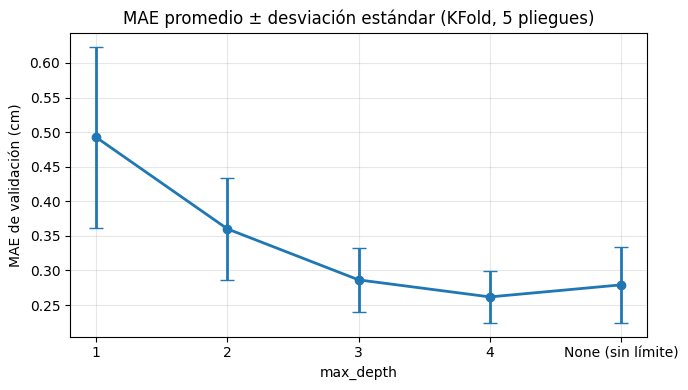

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
x_pos = np.arange(len(tabla_cv))
ax.errorbar(x_pos, tabla_cv["MAE promedio (cm)"], yerr=tabla_cv["Desv. estándar MAE (cm)"],
            marker="o", capsize=5, linewidth=2)
ax.set_xticks(x_pos)
ax.set_xticklabels(tabla_cv["max_depth"])
ax.set_xlabel("max_depth")
ax.set_ylabel("MAE de validación (cm)")
ax.set_title("MAE promedio ± desviación estándar (KFold, 5 pliegues)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretación del gráfico.** La curva tiene forma de **"U" suave**: el error baja mientras el árbol gana capacidad
(de 1 a 4) y sube cuando se deja crecer sin límite. El mínimo está en `max_depth = 4`. Las barras muestran que la
profundidad 1 es la más inestable.

In [11]:
# Selección automática: menor MAE promedio; en empate, la menor profundidad (None se trata como infinito)
orden = tabla_cv.copy()
orden["prof_num"] = [p if p is not None else np.inf for p in profundidades]
orden["MAE_redondeado"] = orden["MAE promedio (cm)"].round(4)
fila_elegida = orden.sort_values(["MAE_redondeado", "prof_num"]).iloc[0]
profundidad_elegida = profundidades[fila_elegida.name]

print(f"Profundidad seleccionada: {profundidad_elegida}")
print(f"MAE promedio de validación: {fila_elegida['MAE promedio (cm)']:.4f} cm "
      f"(± {fila_elegida['Desv. estándar MAE (cm)']:.4f} cm)")

Profundidad seleccionada: 4
MAE promedio de validación: 0.2617 cm (± 0.0374 cm)


**Decisión.** Se selecciona **`max_depth = 4`**, porque obtuvo el **menor MAE promedio de validación cruzada
(≈ 0,262 cm)**. No hubo empate. Esta decisión se tomó **únicamente con los datos de entrenamiento**; el conjunto de
prueba todavía no se ha usado.

In [12]:
# Evidencia complementaria de sobreajuste: error en el propio entrenamiento vs. validación
diag = []
for p in profundidades:
    m = DecisionTreeRegressor(criterion="squared_error", max_depth=p, random_state=SEMILLA).fit(X_train, y_train)
    diag.append({
        "max_depth": str(p) if p is not None else "None (sin límite)",
        "Profundidad real": m.get_depth(),
        "Hojas": m.get_n_leaves(),
        "MAE entrenamiento (cm)": mean_absolute_error(y_train, m.predict(X_train)),
    })
diag = pd.DataFrame(diag)
diag["MAE validación CV (cm)"] = tabla_cv["MAE promedio (cm)"].values
display(diag.round(4))

,max_depth,Profundidad real,Hojas,MAE entrenamiento (cm),MAE validación CV (cm)
0,1,1,2,0.487,0.492
1,2,2,4,0.325,0.360
2,3,3,8,0.234,0.286
3,4,4,14,0.169,0.262
4,None (sin límite),13,110,0.006,0.279


**Interpretación.** Esta tabla es solo diagnóstica (no cambia la selección). El árbol sin límite llega a profundidad
**13** con **110 hojas** para 120 flores: prácticamente una hoja por flor, y su MAE de entrenamiento es casi **0**
(≈ 0,006 cm). Sin embargo, su MAE de validación (≈ 0,279 cm) es peor que el de profundidad 4. Esa brecha grande entre
entrenamiento y validación es la señal típica de **sobreajuste**. Con profundidad 4 (14 hojas) la brecha es mucho menor
(≈ 0,17 vs. ≈ 0,26 cm).

## 6. Entrenamiento y evaluación final

Se entrena un árbol nuevo con `max_depth = 4` usando **las 120 flores de entrenamiento completas** y se evalúa **una
sola vez** sobre las 30 flores de prueba. Las métricas:

- **MAE** (cm): promedio de los errores absolutos $|y - \hat y|$. Es el error típico en las mismas unidades de *y*.
- **RMSE** (cm): raíz del promedio de los errores al cuadrado. Penaliza más los errores grandes; siempre RMSE ≥ MAE.
- **R²** (sin unidades): proporción de la **varianza** de *y* en prueba que explica el modelo frente a predecir
  siempre la media. **No** es un porcentaje de predicciones correctas (en regresión no hay "aciertos").

In [13]:
modelo_final = DecisionTreeRegressor(criterion="squared_error", max_depth=profundidad_elegida, random_state=SEMILLA)
modelo_final.fit(X_train, y_train)

y_pred = modelo_final.predict(X_test)

mae_test = mean_absolute_error(y_test, y_pred)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred))
r2_test = r2_score(y_test, y_pred)

print(f"Profundidad: {modelo_final.get_depth()} | Hojas: {modelo_final.get_n_leaves()}")
print(f"MAE  en prueba: {mae_test:.4f} cm")
print(f"RMSE en prueba: {rmse_test:.4f} cm")
print(f"R²   en prueba: {r2_test:.4f}")

Profundidad: 4 | Hojas: 14
MAE  en prueba: 0.2385 cm
RMSE en prueba: 0.2906 cm
R²   en prueba: 0.9742


**Interpretación de las métricas.**

- **MAE ≈ 0,239 cm:** en promedio, la longitud del pétalo predicha se aleja de la real unos **2,4 milímetros**. Frente a
  un rango de 1,0 a 6,9 cm y una desviación estándar de ≈ 1,77 cm, es un error pequeño.
- **RMSE ≈ 0,291 cm:** es algo mayor que el MAE, lo que indica que hay algunos errores más grandes que el promedio
  (el RMSE los penaliza más), pero no hay errores extremos: si los hubiera, el RMSE sería mucho mayor que el MAE.
- **R² ≈ 0,974:** el modelo explica alrededor del **97 % de la variabilidad** de la longitud del pétalo en las flores de
  prueba, comparado con un modelo que siempre predijera el promedio. **No** significa que el 97 % de las predicciones
  sean correctas.
- **Comparación con la validación cruzada:** el MAE de prueba (≈ 0,239 cm) es muy cercano al MAE promedio de
  validación (≈ 0,262 cm ± 0,037), e incluso algo menor; queda dentro de la variación observada entre pliegues. Esto
  sugiere que la estimación de la validación cruzada fue realista y que el modelo **no está sobreajustado** a las
  particiones. Que sea un poco menor se explica por el azar de qué 30 flores quedaron en prueba (y porque el modelo
  final se entrenó con 120 flores en lugar de 96), no porque el modelo sea "mejor".

In [14]:
# Referencia: modelo ingenuo que siempre predice la media de y_train (no se usa para elegir nada)
pred_media = np.full(len(y_test), y_train.mean())
print(f"MAE de predecir siempre la media de entrenamiento ({y_train.mean():.3f} cm): "
      f"{mean_absolute_error(y_test, pred_media):.4f} cm")
print(f"Reducción del MAE lograda por el árbol: {1 - mae_test / mean_absolute_error(y_test, pred_media):.1%}")

MAE de predecir siempre la media de entrenamiento (3.727 cm): 1.6429 cm
Reducción del MAE lograda por el árbol: 85.5%


**Interpretación.** Un modelo sin información (predecir siempre ≈ 3,73 cm) tendría un MAE de ≈ 1,64 cm en prueba. El
árbol reduce ese error en **más del 85 %**, lo que confirma que los predictores aportan mucha información sobre la
longitud del pétalo. Este cálculo es solo una referencia para interpretar el MAE.

In [15]:
tabla_pred = pd.DataFrame({
    "longitud_petalo_real (cm)": y_test,
    "prediccion (cm)": y_pred,
})
tabla_pred["error (real - pred, cm)"] = tabla_pred["longitud_petalo_real (cm)"] - tabla_pred["prediccion (cm)"]
tabla_pred["error_absoluto (cm)"] = tabla_pred["error (real - pred, cm)"].abs()
tabla_pred = X_test.join(tabla_pred)
tabla_pred = tabla_pred.sort_values("error_absoluto (cm)", ascending=False)

display(tabla_pred.round(3))
print(f"Predicciones distintas en prueba: {np.unique(y_pred.round(4)).size} "
      f"(el árbol tiene {modelo_final.get_n_leaves()} hojas)")
print(f"Errores absolutos ≤ 0,30 cm: {(tabla_pred['error_absoluto (cm)'] <= 0.30).sum()} de {len(tabla_pred)}")

,longitud_sepalo,ancho_sepalo,ancho_petalo,longitud_petalo_real (cm),prediccion (cm),"error (real - pred, cm)",error_absoluto (cm)
56,6.3,3.3,1.6,4.7,5.441,-0.741,0.741
64,5.6,2.9,1.3,3.6,4.177,-0.577,0.577
143,6.8,3.2,2.3,5.9,5.441,0.459,0.459
118,7.7,2.6,2.3,6.9,6.525,0.375,0.375
104,6.5,3.0,2.2,5.8,5.441,0.359,0.359
108,6.7,2.5,1.8,5.8,5.441,0.359,0.359
12,4.8,3.0,0.1,1.4,1.750,-0.350,0.350
45,4.8,3.0,0.3,1.4,1.750,-0.350,0.350
141,6.9,3.1,2.3,5.1,5.441,-0.341,0.341
110,6.5,3.2,2.0,5.1,5.441,-0.341,0.341


Predicciones distintas en prueba: 10 (el árbol tiene 14 hojas)
Errores absolutos ≤ 0,30 cm: 19 de 30


**Interpretación de la tabla (ordenada de mayor a menor error).**

- Varias flores reciben **exactamente la misma predicción** (por ejemplo 5,441 cm, 4,177 cm o 1,443 cm): son flores que
  cayeron en la misma hoja y reciben el promedio de esa hoja. Esto evidencia la naturaleza **escalonada** del árbol.
- **19 de las 30 flores** tienen un error absoluto ≤ 0,30 cm y algunas predicciones son casi exactas (flor 26: error 0).
  Solo 10 valores de predicción distintos aparecen en prueba, de las 14 hojas del árbol.

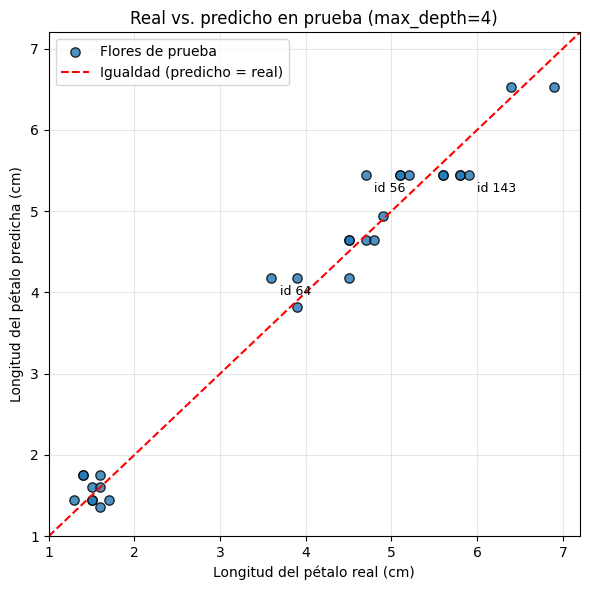

In [16]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, y_pred, s=45, alpha=0.8, edgecolor="k", label="Flores de prueba")
lim = [min(y_test.min(), y_pred.min()) - 0.3, max(y_test.max(), y_pred.max()) + 0.3]
ax.plot(lim, lim, "r--", linewidth=1.5, label="Igualdad (predicho = real)")
for idx in tabla_pred.index[:3]:
    ax.annotate(f"id {idx}", (y_test[idx], tabla_pred.loc[idx, "prediccion (cm)"]),
                xytext=(6, -12), textcoords="offset points", fontsize=9)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Longitud del pétalo real (cm)")
ax.set_ylabel("Longitud del pétalo predicha (cm)")
ax.set_title(f"Real vs. predicho en prueba (max_depth={profundidad_elegida})")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretación del gráfico.** Los puntos se ubican muy cerca de la **línea de igualdad**, lo que es coherente con el
R² alto. Se ven **filas horizontales** de puntos: flores con longitudes reales distintas que reciben la misma
predicción (misma hoja). Hay dos zonas bien separadas: pétalos cortos (≈ 1–2 cm, *setosa*) con errores muy pequeños, y
pétalos largos (≈ 3,5–7 cm) donde están los errores mayores.

In [17]:
print("Hoja (valor) asignado a las 3 flores con mayor error y estadísticas de su hoja en entrenamiento:\n")
hojas_train = modelo_final.apply(X_train)
for idx in tabla_pred.index[:3]:
    hoja = modelo_final.apply(X_test.loc[[idx]])[0]
    y_hoja = y_train[hojas_train == hoja]
    print(f"Flor id {idx}: real = {y_test[idx]:.2f} cm, predicho = {tabla_pred.loc[idx, 'prediccion (cm)']:.3f} cm | "
          f"hoja con {len(y_hoja)} flores de entrenamiento, rango de y en la hoja = [{y_hoja.min():.1f}, {y_hoja.max():.1f}] cm "
          f"| especie (solo para analizar): {datos.loc[idx, 'especie']}")

Hoja (valor) asignado a las 3 flores con mayor error y estadísticas de su hoja en entrenamiento:

Flor id 56: real = 4.70 cm, predicho = 5.441 cm | hoja con 17 flores de entrenamiento, rango de y en la hoja = [4.9, 6.0] cm | especie (solo para analizar): versicolor
Flor id 64: real = 3.60 cm, predicho = 4.177 cm | hoja con 13 flores de entrenamiento, rango de y en la hoja = [3.9, 4.5] cm | especie (solo para analizar): versicolor
Flor id 143: real = 5.90 cm, predicho = 5.441 cm | hoja con 17 flores de entrenamiento, rango de y en la hoja = [4.9, 6.0] cm | especie (solo para analizar): virginica


**Análisis de los errores más grandes.**

1. **Flor 56 (error ≈ 0,74 cm):** real 4,7 cm, predicción 5,44 cm. Es una *versicolor* con sépalo largo (6,3 cm) y
   pétalo relativamente ancho (1,6 cm), medidas típicas de *virginica*. Por eso cae en una hoja dominada por flores
   de pétalo largo (rango 4,9–6,0 cm, promedio 5,44 cm). Su longitud real (4,7 cm) está **por debajo de todas** las
   flores de entrenamiento de esa hoja: el árbol no puede predecir algo distinto del promedio de la hoja.
2. **Flor 64 (error ≈ 0,58 cm):** real 3,6 cm, predicción 4,18 cm. Es una *versicolor* con pétalo inusualmente corto
   para sus otras medidas; cae en una hoja de versicolor "típicas" (rango 3,9–4,5 cm) y su valor real queda por
   debajo de todas ellas.
3. **Flor 143 (error ≈ 0,46 cm):** real 5,9 cm, predicción 5,44 cm. Es una *virginica* grande que comparte hoja con
   flores de pétalos más cortos; el promedio de la hoja la subestima.

**Patrón:** los errores grandes se concentran en la **zona de transición entre versicolor y virginica**, donde las medidas
se superponen, y se deben a que cada hoja da un **valor constante**. Las *setosa* tienen errores pequeños porque su
grupo está claramente separado. **No se modifica la profundidad** a partir de esta evaluación: hacerlo sería usar la
prueba para ajustar el modelo y su resultado dejaría de ser una estimación honesta.

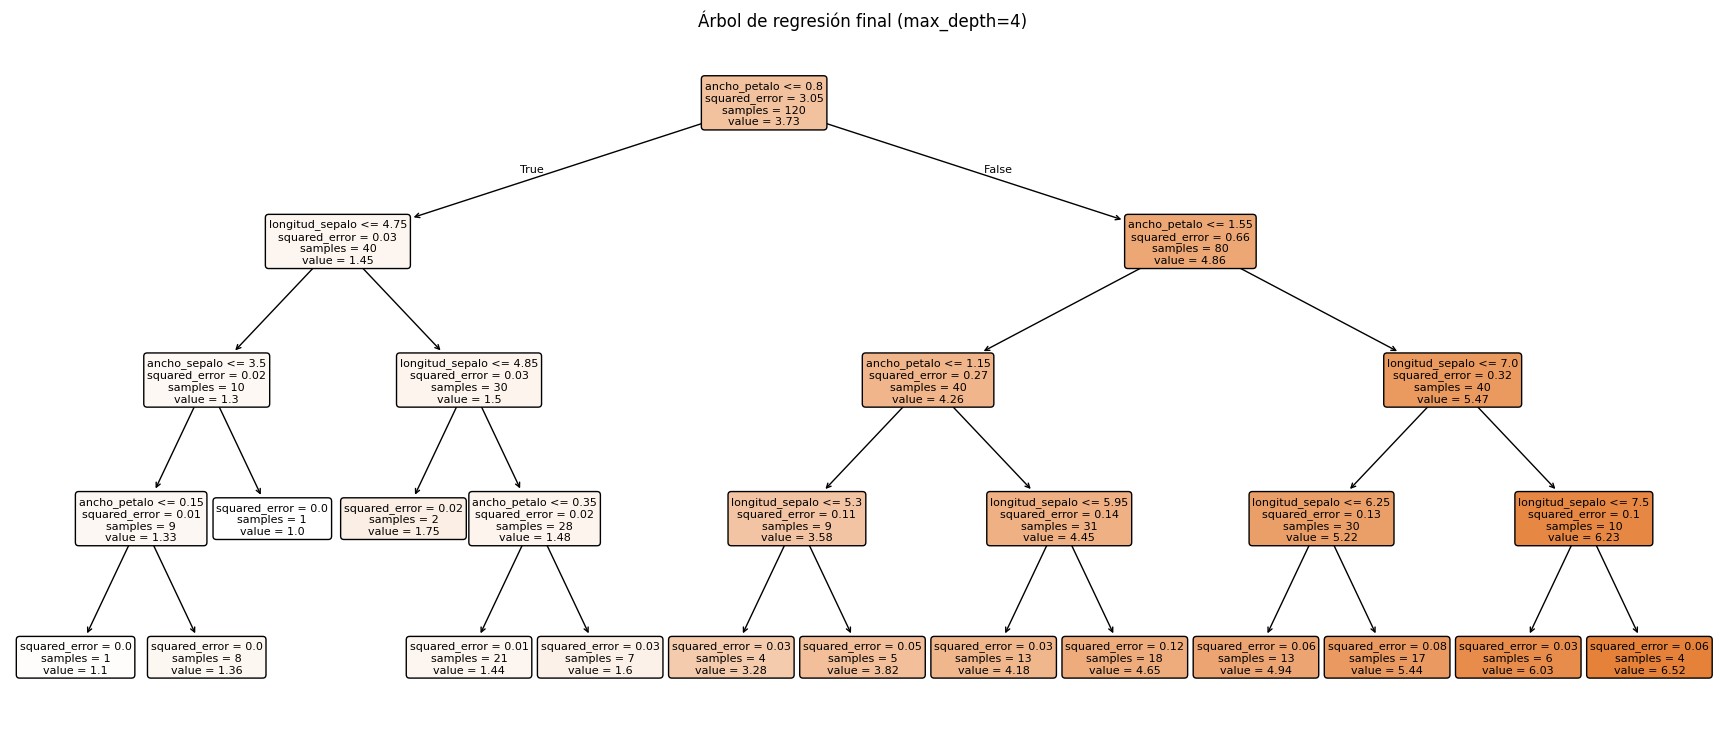

|--- ancho_petalo <= 0.80
|   |--- longitud_sepalo <= 4.75
|   |   |--- ancho_sepalo <= 3.50
|   |   |   |--- ancho_petalo <= 0.15
|   |   |   |   |--- value: [1.10]
|   |   |   |--- ancho_petalo >  0.15
|   |   |   |   |--- value: [1.36]
|   |   |--- ancho_sepalo >  3.50
|   |   |   |--- value: [1.00]
|   |--- longitud_sepalo >  4.75
|   |   |--- longitud_sepalo <= 4.85
|   |   |   |--- value: [1.75]
|   |   |--- longitud_sepalo >  4.85
|   |   |   |--- ancho_petalo <= 0.35
|   |   |   |   |--- value: [1.44]
|   |   |   |--- ancho_petalo >  0.35
|   |   |   |   |--- value: [1.60]
|--- ancho_petalo >  0.80
|   |--- ancho_petalo <= 1.55
|   |   |--- ancho_petalo <= 1.15
|   |   |   |--- longitud_sepalo <= 5.30
|   |   |   |   |--- value: [3.28]
|   |   |   |--- longitud_sepalo >  5.30
|   |   |   |   |--- value: [3.82]
|   |   |--- ancho_petalo >  1.15
|   |   |   |--- longitud_sepalo <= 5.95
|   |   |   |   |--- value: [4.18]
|   |   |   |--- longitud_sepalo >  5.95
|   |   |   |   |--

In [18]:
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(modelo_final, feature_names=predictores, filled=True, rounded=True,
          precision=2, fontsize=8, impurity=True, ax=ax)
ax.set_title(f"Árbol de regresión final (max_depth={profundidad_elegida})")
plt.show()

print(export_text(modelo_final, feature_names=predictores, decimals=2))

**Interpretación del árbol.**

- La **raíz** divide por `ancho_petalo ≤ 0,80 cm`: separa las flores de pétalo corto (≈ 1–1,9 cm, las *setosa*) del
  resto. Es la división que más reduce el error cuadrático, coherente con la correlación de 0,96 observada.
- En la rama derecha, el árbol vuelve a dividir por `ancho_petalo` (≤ 1,55 y ≤ 1,15) y luego por `longitud_sepalo`, que
  ajusta la predicción dentro de cada grupo (sépalos más largos → pétalos más largos).
- Cada recuadro muestra `squared_error` (varianza de *y* en el nodo), `samples` (flores de entrenamiento) y `value`:
  **el promedio de la longitud del pétalo de esas flores, en cm**, que es la predicción en las hojas.
- **Ejemplo de ruta:** una flor con ancho de pétalo 1,3 cm y sépalo de 5,6 cm sigue `ancho_petalo > 0,80` →
  `≤ 1,55` → `> 1,15` → `longitud_sepalo ≤ 5,95` y llega a una hoja con valor **≈ 4,18 cm**.
- `ancho_sepalo` casi no se usa (solo en una división profunda de la rama de pétalos cortos), lo que coincide con su
  correlación débil.

In [19]:
# Complemento (solo entrenamiento, mismos pliegues): regresión lineal como punto de comparación conceptual
mae_lineal = -cross_val_score(LinearRegression(), X_train, y_train, cv=cv, scoring="neg_mean_absolute_error")
print(f"Regresión lineal  - MAE CV: {mae_lineal.mean():.4f} ± {mae_lineal.std():.4f} cm")
print(f"Árbol (max_depth={profundidad_elegida}) - MAE CV: {fila_elegida['MAE promedio (cm)']:.4f} ± "
      f"{fila_elegida['Desv. estándar MAE (cm)']:.4f} cm")
lin = LinearRegression().fit(X_train, y_train)
print("\nCoeficientes de la regresión lineal (cm de pétalo por cada cm del predictor):")
print(pd.Series(lin.coef_, index=predictores).round(3))

Regresión lineal  - MAE CV: 0.2482 ± 0.0344 cm
Árbol (max_depth=4) - MAE CV: 0.2617 ± 0.0374 cm

Coeficientes de la regresión lineal (cm de pétalo por cada cm del predictor):
longitud_sepalo    0.723
ancho_sepalo      -0.636
ancho_petalo       1.468
dtype: float64


**Interpretación (complemento, no forma parte de la selección).** Con los mismos pliegues, una regresión lineal obtiene
un MAE de validación similar al del árbol (≈ 0,248 cm frente a ≈ 0,262 cm). Esto ilustra la diferencia entre ambos
modelos:

- La regresión lineal estima **un coeficiente por predictor** (por ejemplo, ≈ +1,47 cm de pétalo por cada cm de ancho
  de pétalo) y produce predicciones **continuas**. Como la relación en Iris es casi lineal (r ≈ 0,96), este modelo
  sencillo funciona muy bien.
- El árbol **no supone linealidad**: aprende reglas por umbrales y predice con **14 valores posibles** (uno por hoja).
  Esa "discretización" le cuesta algo de precisión cuando la relación real es suave, pero lo hace interpretable mediante
  reglas y capaz de captar relaciones no lineales e interacciones si existieran.

El objetivo de la actividad es el árbol de regresión, por eso el modelo evaluado sigue siendo el árbol con
`max_depth = 4`; esta comparación solo ayuda a reconocer una de sus limitaciones.

## 7. Respuestas a las preguntas guía

**1. ¿Por qué este problema es de regresión y qué representa el valor de una hoja?**
Porque la variable objetivo, la longitud del pétalo, es una **medida numérica continua en centímetros**, no una
categoría. Predecir la especie (setosa, versicolor, virginica) sería clasificación. En el árbol de regresión, el valor
de una hoja es el **promedio de la longitud del pétalo de las flores de entrenamiento que llegaron a esa hoja**; toda
flor nueva que caiga allí recibe ese promedio como predicción (por ejemplo, 5,44 cm en la hoja de las flores 56 y 143).

**2. ¿En qué se diferencia el modelo empleado de una regresión lineal?**
La regresión lineal ajusta una ecuación $\hat y = \beta_0 + \sum \beta_j x_j$, con efecto constante de cada predictor y
predicciones continuas que pueden extrapolar. El árbol divide los datos con reglas *si–entonces* sobre umbrales y predice
un valor constante por región (función escalonada, 14 valores posibles con profundidad 4), no supone linealidad,
no necesita escalar variables y no puede predecir fuera del rango de *y* visto en entrenamiento. En la sección 6 se
observó que, al ser la relación casi lineal en Iris, ambos obtienen errores similares.

**3. ¿Aumentar la profundidad siempre redujo el error de validación? Justifique con la tabla.**
No. El MAE promedio bajó de 0,492 cm (profundidad 1) a 0,360, 0,286 y 0,262 cm (profundidades 2, 3 y 4), pero con
`max_depth=None` subió a 0,279 cm y su desviación estándar aumentó (0,037 → 0,054 cm). El árbol sin límite alcanzó
profundidad 13 y 110 hojas, con MAE de entrenamiento casi 0: memorizó los datos (**sobreajuste**). Más complejidad
ayuda hasta un punto; después perjudica la generalización.

**4. ¿Qué significa su MAE en centímetros y cómo se compara con el MAE de prueba?**
El MAE de validación cruzada del modelo elegido (≈ 0,262 cm) significa que, en flores no usadas para entrenar, el árbol
se equivoca en promedio unos 2,6 mm al estimar la longitud del pétalo. En prueba el MAE fue ≈ 0,239 cm, muy cercano y
dentro de la variación entre pliegues (± 0,037 cm). Esto indica que la validación cruzada estimó bien el desempeño y que
el modelo generaliza de forma consistente.

**5. ¿Por qué se reservaron los datos de prueba y qué limitaciones tiene el modelo?**
Se reservaron para tener una **estimación honesta** del desempeño con flores que no participaron ni en el entrenamiento
ni en la elección de `max_depth`. Si se hubiera usado la prueba para escoger la profundidad, el resultado estaría
sesgado de forma optimista (fuga de información). Limitaciones:
- Predicciones **escalonadas**: solo 14 valores posibles; flores distintas reciben la misma predicción.
- **No extrapola**: nunca predecirá un pétalo más largo que el promedio de la hoja más alta (≈ 6,5 cm) ni más corto que
  la hoja más baja (≈ 1,0 cm), aunque la flor tenga medidas fuera del rango observado.
- Los mayores errores están en la zona donde se superponen *versicolor* y *virginica*.
- **Muestra pequeña** (120 flores de entrenamiento y 30 de prueba): las métricas pueden variar con otra partición, y los
  árboles son **inestables** (pequeños cambios en los datos pueden cambiar sus reglas).
- Solo es válido para flores Iris de estas tres especies y medidas similares; no se debe generalizar a otras plantas.

## 8. Conclusión

En este seguimiento se adaptó Iris a un problema de **regresión**: predecir la longitud del pétalo (cm) a partir de la
longitud y el ancho del sépalo y el ancho del pétalo, excluyendo la especie. Con validación cruzada KFold de 5 pliegues,
aplicada solo sobre las 120 flores de entrenamiento, se compararon cinco profundidades y se eligió **`max_depth = 4`**
por tener el menor MAE promedio (≈ 0,262 cm ± 0,037). La tabla mostró que más profundidad no siempre es mejor: el árbol
sin límite memorizó el entrenamiento y empeoró en validación (≈ 0,279 cm). Evaluado una sola vez en las 30 flores de
prueba, el modelo obtuvo **MAE ≈ 0,239 cm, RMSE ≈ 0,291 cm y R² ≈ 0,974**, resultados coherentes con la validación
cruzada. Los mayores errores (hasta ≈ 0,74 cm) aparecieron en flores de la zona de transición versicolor–virginica,
debido a que cada hoja predice un promedio constante. El modelo es preciso e interpretable, pero su salida escalonada,
su incapacidad para extrapolar y el tamaño reducido de la muestra limitan su generalización.

## 9. Referencias

1. scikit-learn developers. *1.10. Decision Trees* (User Guide). https://scikit-learn.org/stable/modules/tree.html
2. scikit-learn developers. *sklearn.tree.DecisionTreeRegressor* (API). https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html
3. scikit-learn developers. *3.1. Cross-validation: evaluating estimator performance*. https://scikit-learn.org/stable/modules/cross_validation.html
4. scikit-learn developers. *sklearn.model_selection.KFold* (API). https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html
5. scikit-learn developers. *3.4. Metrics and scoring: quantifying the quality of predictions* (MAE, MSE, R²). https://scikit-learn.org/stable/modules/model_evaluation.html
6. Breiman, L., Friedman, J., Olshen, R. y Stone, C. (1984). *Classification and Regression Trees*. Wadsworth.
7. James, G., Witten, D., Hastie, T. y Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2.ª ed.), cap. 8: Tree-Based Methods. Springer. https://www.statlearning.com
8. Gómez Meneses, L. M. (2026). *Analítica de Datos — Clase 8: Árboles de decisión y validación cruzada*; Laboratorios 17 y 18. Universidad Cooperativa de Colombia.